# Chapitre 12 - Exercices 12.11 à 12.15

Ces exercices accompagnent la section *Doing the Right Thing* (cours 6 et 7). Le livre
n'a ni calculs ni code sur ces sujets ; les exercices donnent des ordres de grandeur et
des mécanismes vérifiables, sans prétendre réduire l'éthique à des formules :

- **12.11** : calibration contre égalité des taux d'erreur, un théorème
  d'impossibilité (calcul et simulation) ;
- **12.12** : combien de personnes sont ré-identifiables, et à quel prix
  les protéger (calcul et mini-lab) ;
- **12.13** : réponse randomisée, taille d'échantillon et déni plausible
  (calcul et simulation) ;
- **12.14** : boucle de rétroaction des patrouilles et correction de
  l'échantillonnage (mini-lab) ;
- **12.15** : durée de conservation, agrégation et risque de fuite
  (calcul et simulation).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 12.11 : calibration contre égalité des taux d'erreur

**Énoncé.** Un score prédit la probabilité de défaut de paiement. On refuse le crédit
quand le score dépasse un seuil. Pour un groupe de personnes, on note $\pi$ le taux de
base (proportion réelle de défauts), $\mathrm{FPR}$ la part des bons payeurs refusés,
$\mathrm{FNR}$ la part des mauvais payeurs acceptés, $\mathrm{PPV}$ la part de vrais
défauts parmi les refusés.

1. Montrer l'identité $\mathrm{FPR} = \dfrac{\pi}{1-\pi}\cdot\dfrac{1-\mathrm{PPV}}{\mathrm{PPV}}\cdot(1-\mathrm{FNR})$.
2. Deux groupes ont des taux de base différents, $\pi_A = 0{,}2$ et $\pi_B = 0{,}4$. On
   exige la même précision des refus ($\mathrm{PPV} = 0{,}6$) et le même taux de mauvais
   payeurs acceptés ($\mathrm{FNR} = 0{,}3$) dans les deux groupes. Calculer le
   $\mathrm{FPR}$ de chaque groupe. Conclure.
3. Vérifier par simulation : générer un score **parfaitement calibré** dans chaque
   groupe, appliquer un seuil commun de 0,5, et mesurer FPR, FNR et PPV par groupe.
4. Que faut-il en retenir pour l'ingénieur qui « choisit une métrique d'équité » ?

**Rappels.** Cours 6, section 2 (sous-section *Bias and discrimination*) : un modèle peut sembler juste selon un
critère et injuste selon un autre ; la calibration (à score égal, même taux observé)
est l'un des critères possibles.

**Solution.**

*1.* Sur $n$ personnes : $n\pi$ mauvais payeurs, dont $\mathrm{TP} = n\pi(1-\mathrm{FNR})$
refusés ; $n(1-\pi)$ bons payeurs, dont $\mathrm{FP} = n(1-\pi)\mathrm{FPR}$ refusés. Par
définition $\mathrm{PPV} = \mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$, donc
$\mathrm{FP} = \mathrm{TP}\,(1-\mathrm{PPV})/\mathrm{PPV}$. En remplaçant :
$n(1-\pi)\mathrm{FPR} = n\pi(1-\mathrm{FNR})(1-\mathrm{PPV})/\mathrm{PPV}$, d'où l'identité.

*2.* $\mathrm{FPR}_A = \tfrac{0{,}2}{0{,}8}\cdot\tfrac{0{,}4}{0{,}6}\cdot 0{,}7 \approx 0{,}117$ et
$\mathrm{FPR}_B = \tfrac{0{,}4}{0{,}6}\cdot\tfrac{0{,}4}{0{,}6}\cdot 0{,}7 \approx 0{,}311$. À
précision et taux de faux négatifs égaux, les bons payeurs du groupe B sont refusés
**près de 2,7 fois plus souvent**. Dès que les taux de base diffèrent (et que le
classifieur n'est pas parfait), on ne peut pas égaliser à la fois PPV, FNR et FPR :
c'est le théorème d'impossibilité de Chouldechova (2017), proche de celui de Kleinberg,
Mullainathan et Raghavan sur la calibration.

*3.* Voir la vérification. *4.* Le choix d'une métrique d'équité n'est pas technique :
chaque critère protège un intérêt différent (la banque veut un PPV égal, le bon payeur
veut un FPR égal). Il faut l'expliciter, le justifier, et se demander d'abord **pourquoi**
les taux de base diffèrent : si c'est l'effet de discriminations passées dans les
étiquettes (cours 6), aucune métrique calculée sur ces étiquettes ne le
révélera.

**Vérification** : calcul direct de la question 2, puis simulation. Dans chaque groupe,
le score $s$ suit une loi bêta de moyenne $\pi_g$, et le défaut survient avec
probabilité exactement $s$ : le score est calibré par construction.

FPR_A = 0.117 ; FPR_B = 0.311


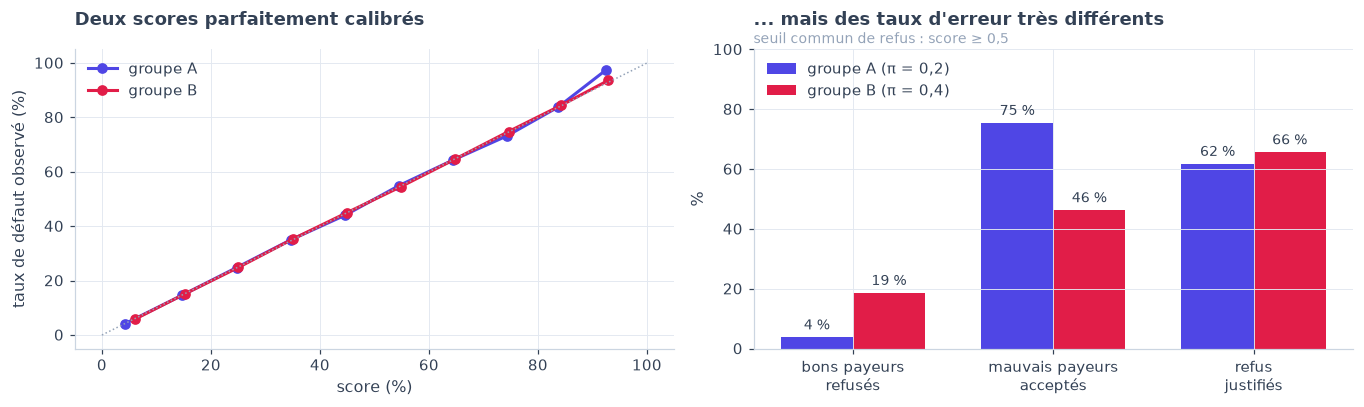

,taux de base,FPR (bons refusés),FNR (mauvais acceptés),PPV (refus justifiés)
groupe,,,,
A,0.200,0.038,0.755,0.618
B,0.399,0.186,0.463,0.657


In [2]:
def fpr_identity(pi, ppv, fnr):
    return pi / (1 - pi) * (1 - ppv) / ppv * (1 - fnr)

print(f"FPR_A = {fpr_identity(0.2, 0.6, 0.3):.3f} ; FPR_B = {fpr_identity(0.4, 0.6, 0.3):.3f}")

n = 200_000
rows, cal = [], []
for gname, pi in [("A", 0.2), ("B", 0.4)]:
    conc = 4.0
    s = rng.beta(pi * conc, (1 - pi) * conc, size=n)
    y = rng.random(n) < s                       # défaut
    refuse = s >= 0.5
    rows.append({"groupe": gname, "taux de base": y.mean(), "FPR (bons refusés)": refuse[~y].mean(),
                 "FNR (mauvais acceptés)": (~refuse[y]).mean(), "PPV (refus justifiés)": y[refuse].mean()})
    bins = np.linspace(0, 1, 11)
    idx = np.digitize(s, bins[1:-1])
    cal.append((gname, [s[idx == b].mean() for b in range(10)], [y[idx == b].mean() for b in range(10)]))
R = pd.DataFrame(rows).set_index("groupe")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
for (gname, sx, yx), c in zip(cal, [INDIGO, ROSE]):
    ax.plot(np.array(sx) * 100, np.array(yx) * 100, "o-", color=c, label=f"groupe {gname}")
ax.plot([0, 100], [0, 100], ":", color=GRAY, lw=1)
ax.set_xlabel("score (%)"); ax.set_ylabel("taux de défaut observé (%)")
ax.set_title("Deux scores parfaitement calibrés")
ax.legend()
ax = axes[1]
x = np.arange(3)
cols = ["FPR (bons refusés)", "FNR (mauvais acceptés)", "PPV (refus justifiés)"]
ax.bar(x - 0.18, R.loc["A", cols] * 100, 0.36, color=INDIGO, label="groupe A (π = 0,2)")
ax.bar(x + 0.18, R.loc["B", cols] * 100, 0.36, color=ROSE, label="groupe B (π = 0,4)")
annotate_bars(ax, "{:.0f} %")
ax.set_xticks(x, ["bons payeurs\nrefusés", "mauvais payeurs\nacceptés", "refus\njustifiés"])
ax.set_ylim(0, 100); ax.set_ylabel("%")
ax.set_title("... mais des taux d'erreur très différents")
subtitle(ax, "seuil commun de refus : score ≥ 0,5")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
R

Les deux scores sont calibrés (les courbes suivent la diagonale), mais avec le même
seuil le groupe B, au taux de base plus élevé, voit ses bons payeurs refusés bien plus
souvent, et ses mauvais payeurs moins souvent acceptés. Changer de seuil par groupe
égaliserait certains taux et en déséquilibrerait d'autres : l'identité de la question
1 l'impose.

> **À retenir.** Quand les taux de base diffèrent, calibration, égalité des taux de
> faux positifs et égalité des taux de faux négatifs sont incompatibles. Choisir un
> critère d'équité est un choix de valeurs, à expliciter et à assumer, pas un détail
> d'implémentation.